# Decision Trees and Random Forest Exercise

We want to analyze lending club data: [LendingClub.com](www.lendingclub.com). Lending Club connects borrowers with investors. 

**We want to predict who will pay back (target column: not.fully.paid)**

Data source reference: [here](https://www.lendingclub.com/info/download-data.action) 

Data set features:

* credit.policy: 1 if the customer meets the credit underwriting criteria of LendingClub.com, and 0 otherwise.
* purpose: The purpose of the loan (takes values "credit_card", "debt_consolidation", "educational", "major_purchase", "small_business", and "all_other").
* int.rate: The interest rate of the loan, as a proportion (a rate of 11% would be stored as 0.11). Borrowers judged by LendingClub.com to be more risky are assigned higher interest rates.
* installment: The monthly installments owed by the borrower if the loan is funded.
* log.annual.inc: The natural log of the self-reported annual income of the borrower.
* dti: The debt-to-income ratio of the borrower (amount of debt divided by annual income).
* fico: The FICO credit score of the borrower.
* days.with.cr.line: The number of days the borrower has had a credit line.
* revol.bal: The borrower's revolving balance (amount unpaid at the end of the credit card billing cycle).
* revol.util: The borrower's revolving line utilization rate (the amount of the credit line used relative to total credit available).
* inq.last.6mths: The borrower's number of inquiries by creditors in the last 6 months.
* delinq.2yrs: The number of times the borrower had been 30+ days past due on a payment in the past 2 years.
* pub.rec: The borrower's number of derogatory public records (bankruptcy filings, tax liens, or judgments).

# Import Libraries

**Import the usual libraries for pandas and plotting. You can import sklearn later on.**

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## 1. Get the Data (loan_data.csv)

In [35]:
loans = pd.read_csv('loan_data.csv')

## 2. Check out the info(), head(), and describe() methods on the dataset

In [36]:
loans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   object 
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), object(1)
memory usage: 1.0+ MB


In [37]:
loans.describe()

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000


In [38]:
loans.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [39]:
loans['credit.policy'].value_counts()

credit.policy
1    7710
0    1868
Name: count, dtype: int64

# Exploratory Data Analysis (EDA)

### 3. Create a histogram of two FICO distributions on top of each other, one for each credit.policy (1 and 0)
*(hint: you may want to create two histograms in 2 lines using pandas built-in visualization )*

<Axes: >

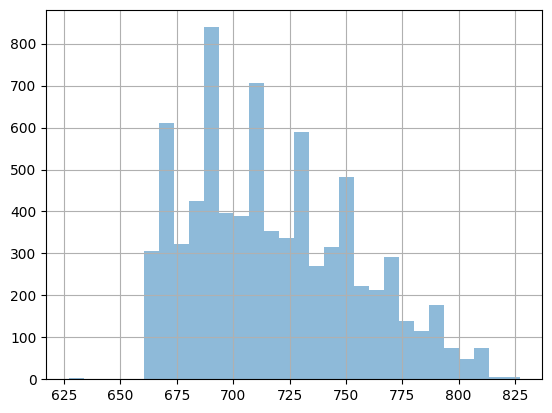

In [40]:
loans[loans['credit.policy'] == 1]['fico'].hist(alpha=0.5, bins=30, label='Credit.Policy=1')

### 4. Create the same histrogram, now for not.fully.paid column 

<Axes: >

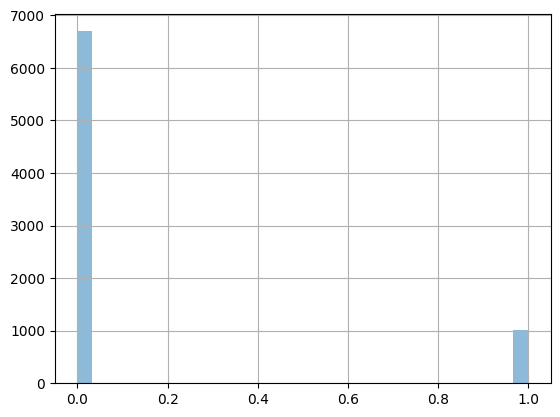

In [41]:
loans[loans['credit.policy'] == 1]['not.fully.paid'].hist(alpha=0.5, bins=30)

### 5. Create a count plot for *purpose* column with hue set to *not.fully.paid* 

<Axes: xlabel='purpose', ylabel='count'>

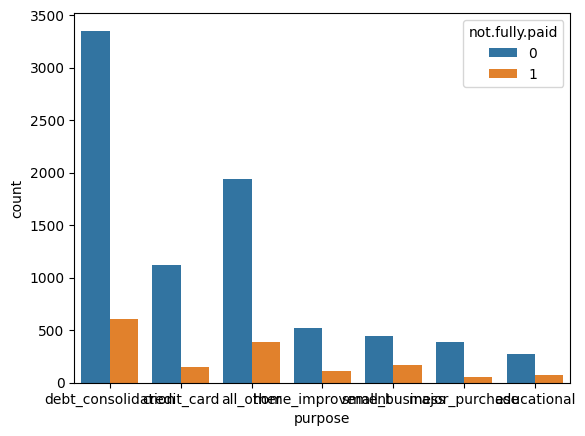

In [42]:
sns.countplot(x='purpose', hue='not.fully.paid', data=loans)

### 6. Create a jointplot of fico vs. int.rate with hue set to *not.fully.paid*. What is your interpretation from this plot?  

<Axes: xlabel='fico', ylabel='int.rate'>

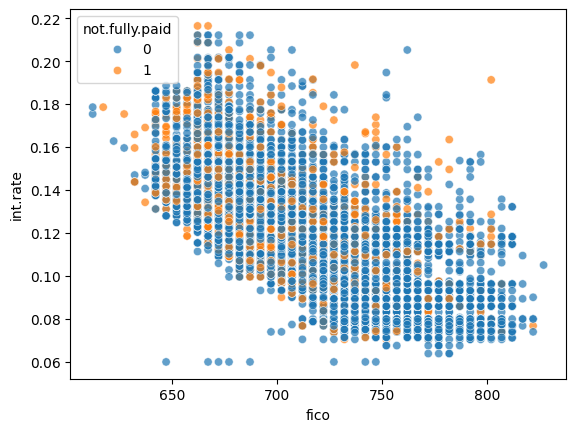

In [43]:
sns.scatterplot(x='fico', y='int.rate', hue='not.fully.paid', data=loans, alpha=0.7)


### 7. Create a lmpplot() for fico vs. int.rate with hue set to *credit.policy* and col set to 'not.fully.paid'. What is your interpretation from this plot? 

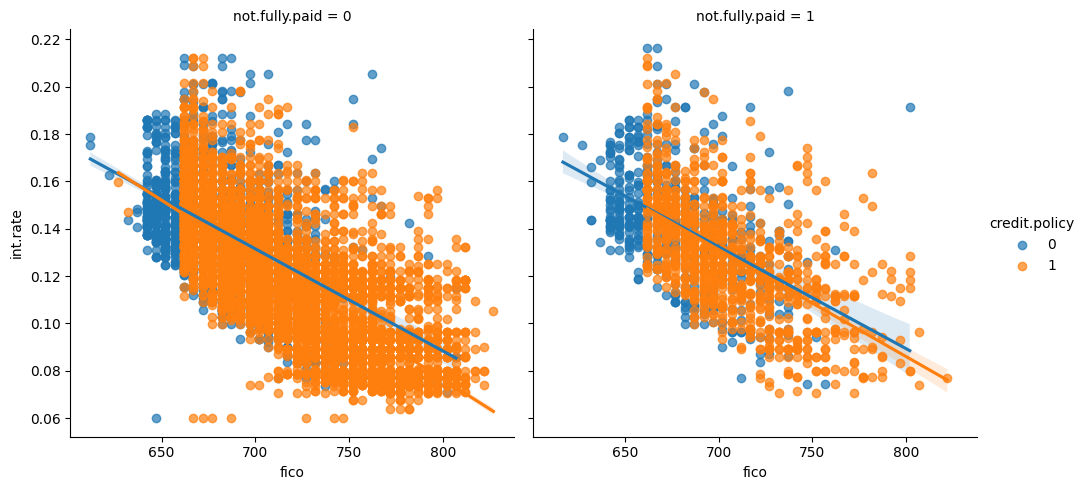

In [44]:
sns.lmplot(x='fico', y='int.rate', hue='credit.policy', col='not.fully.paid', data=loans, scatter_kws={'alpha':0.7})


# Feature engineering 

In [45]:
loans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   object 
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), object(1)
memory usage: 1.0+ MB


In [46]:
loans.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


## Categorical Features

### 8. *purpose* column is categorical. Transform it into dummy variables 

*hint: .get_dummies(loans,columns=['purpose'],drop_first=True)*

In [47]:
purpose = pd.get_dummies(loans, columns=['purpose'], drop_first=True)
purpose.head()

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,1,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0,False,True,False,False,False,False
1,1,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0,True,False,False,False,False,False
2,1,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0,False,True,False,False,False,False
3,1,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0,False,True,False,False,False,False
4,1,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0,True,False,False,False,False,False


# Model development

### 9. Set X and y and split your data

In [48]:
from sklearn.model_selection import train_test_split

In [49]:
X = purpose.drop('not.fully.paid', axis=1)
y = purpose['not.fully.paid']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)


### 10. Train your Decision Tree Classifier

In [50]:
from sklearn.tree import DecisionTreeClassifier

In [51]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [52]:
dt_predictions = dt_model.predict(X_test)

### 11. Evaluate your Decision Tree Classifier

In [53]:
from sklearn.metrics import classification_report, confusion_matrix

In [54]:
print("Decision Tree Classification Report:")
print(classification_report(y_test, dt_predictions))

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.84      0.84      2650
           1       0.21      0.22      0.21       511

    accuracy                           0.74      3161
   macro avg       0.53      0.53      0.53      3161
weighted avg       0.74      0.74      0.74      3161



In [55]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, dt_predictions))

Confusion Matrix:
[[2223  427]
 [ 400  111]]


### 12. Train your Random Forest Classifier

In [56]:
from sklearn.ensemble import RandomForestClassifier

In [57]:
rf_model = RandomForestClassifier(random_state=42)

In [58]:
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

### 13.  Evaluate your Random Forest Classifier

In [59]:
print("Random Forest Classification Report:")
print(classification_report(y_test, rf_predictions))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.99      0.91      2650
           1       0.30      0.01      0.03       511

    accuracy                           0.84      3161
   macro avg       0.57      0.50      0.47      3161
weighted avg       0.75      0.84      0.77      3161



In [60]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

Confusion Matrix:
[[2634   16]
 [ 504    7]]


### 14. Which classifier provides a better result? 

In [61]:
## Random Tree Classifier did better it had overall higher values in recall and f1-score and was just about as good in precision

#### This is an unbalanced data set so result is not good, needs  to do more feature engineering 

# END